In [2]:
import os
import sys
project_root = "/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project"
sys.path.insert(0, project_root)
os.chdir(project_root)
from matplotlib import pyplot as plt
import pandas as pd

figures_dir = os.path.join(project_root,"notebooks","figures")

In [3]:
# """Count the number of training FAST files (hence reads) for wick"""
# from main.scripts.constants import TRAIN_DATA
# data_dir = "../wick_data"
# total_fast5_files = 0
# for f in os.listdir(data_dir):
#     if f in TRAIN_DATA:
#         fast5_dir = os.path.join(data_dir, f, "fast5")
#         fast5_files = list(filter(lambda x: os.path.splitext(x)[1] == ".fast5",os.listdir(fast5_dir)))
#         total_fast5_files += len(fast5_files)

# print(total_fast5_files)

In [3]:
LOG_FILE = "../experiments/bacterial_benchmark/log.csv"

df = pd.read_csv(LOG_FILE)

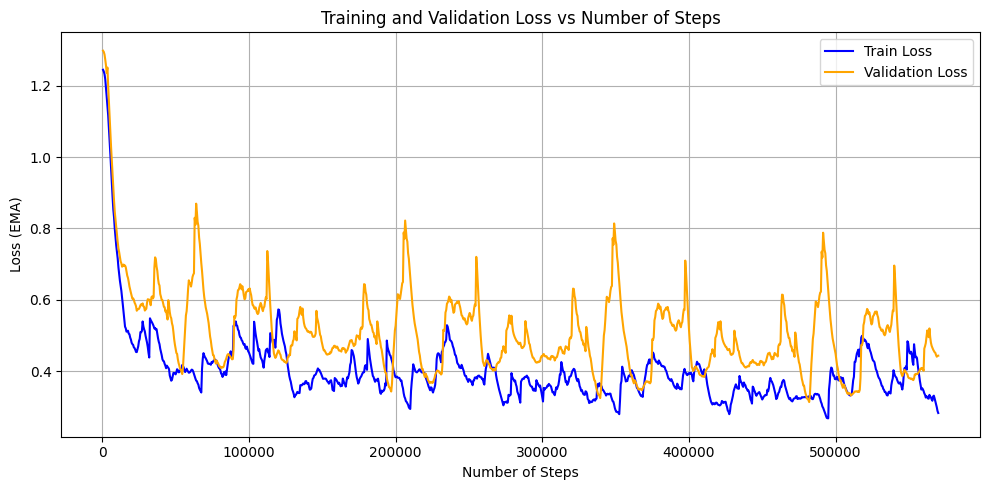

In [ ]:

"""Plot loss curve"""
plt.figure(figsize=(10, 5))
plt.plot(df['num_steps'], df['ema_train_loss'], label='Train Loss', color='blue')
plt.plot(df['num_steps'], df['ema_val_loss'], label='Validation Loss', color='orange')
plt.xlabel('Number of Steps')
plt.ylabel('Loss (EMA)')
plt.title('Training and Validation Loss vs Number of Steps')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir,"benchmark_loss_curves.svg"))
plt.show()

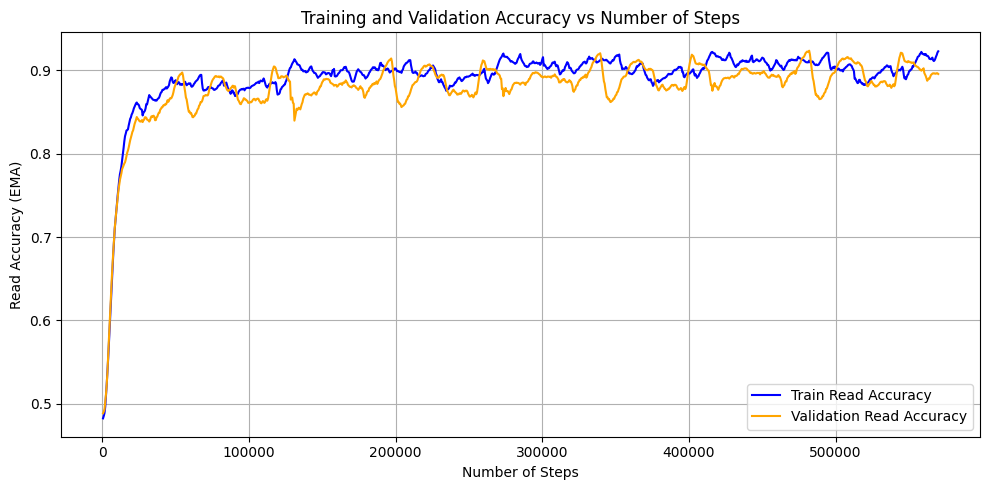

In [5]:

"""Plot accuracy curves"""
plt.figure(figsize=(10, 5))
plt.plot(df['num_steps'], df['ema_train_acc'], label='Train Read Accuracy', color='blue')
plt.plot(df['num_steps'], df['ema_val_acc'], label='Validation Read Accuracy', color='orange')
plt.xlabel('Number of Steps')
plt.ylabel('Read Accuracy (EMA)')
plt.title('Training and Validation Accuracy vs Number of Steps')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir,"benchmark_accuracy_curves.svg"),format="svg")
plt.show()

In [7]:
import json

FLOPS_FILE = "../model_output_4_epochs/flops.json"

# Open and load the JSON file
with open(FLOPS_FILE, 'r') as f:
    flops_data = json.load(f)  # now `data` is a Python dictionary

new_flops_data = {}
# remove any empty entries
for k,v in flops_data.items():
    if v == {}:
        continue
    new_flops_data[k] = v

flops_data = new_flops_data
# print(flops_data)
for k,v in flops_data.items():
    print(k,v)


 {'conv': 3170304000, 'add_': 106496002, 'batch_norm': 81920000, 'layer_norm': 532480000, 'div': 6, 'linear': 151035904000, 'mul': 24, 'scaled_dot_product_attention': 67584000000, 'log_softmax': 4128000}
conv1 {'conv': 24576000}
bn1 {'add_': 1, 'batch_norm': 40960000}
conv2 {'conv': 3145728000}
bn2 {'add_': 1, 'batch_norm': 40960000}
position_encoding {'add_': 8192000}
encoder_layers {'layer_norm': 491520000, 'div': 6, 'linear': 150994944000, 'mul': 24, 'scaled_dot_product_attention': 67584000000, 'add_': 98304000}
encoder_layers.0 {'layer_norm': 81920000, 'div': 1, 'linear': 25165824000, 'mul': 4, 'scaled_dot_product_attention': 11264000000, 'add_': 16384000}
encoder_layers.0.self_attn {'div': 1, 'linear': 8388608000, 'mul': 4, 'scaled_dot_product_attention': 11264000000}
encoder_layers.0.linear1 {'linear': 8388608000}
encoder_layers.0.linear2 {'linear': 8388608000}
encoder_layers.0.norm1 {'layer_norm': 40960000}
encoder_layers.0.norm2 {'layer_norm': 40960000}
encoder_layers.1 {'layer

In [8]:
from main.scripts.constants import TEST_DATA
import statistics

ROOT_RESULTS_DIR = "../model_output_4_epochs/"

eval_dfs = []
alignment_stats_dfs = []
basecall_stats_dfs = []
consensus_eval_dfs = []


# for f in os.listdir(ROOT_RESULTS_DIR):
#     if f in TEST_DATA:
#         eval_dfs.append(pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","evaluation.csv")))
#         alignment_stats_dfs.append(pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","alignment_stats.csv")))
#         basecall_stats_dfs.append(pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"basecall_stats.csv")))
#         consensus_eval_dfs.append(pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","consensus_accuracy.csv")))

for f in os.listdir(ROOT_RESULTS_DIR):
    if f in TEST_DATA:
        eval_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","evaluation.csv")))
        alignment_stats_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"basecall_stats.csv")))
        consensus_eval_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","consensus_accuracy.csv")))
        
        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"])
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)
        consensus_accuracy = consensus_eval_df["Consensus Accuracy"].item()

        print(f"Genome: {f}, read acc: {read_accuracy}, match rate: {match_rate}, mismatch rate: {mismatch_rate}, insertion rate: {insertion_rate}, deletion rate: {deletion_rate}, alignment rate: {alignment_rate}, basecall rate: {basecall_rate}, consensus accuracy: {consensus_accuracy}, original consensus accuracy: N/A")



# eval_df = pd.concat(eval_dfs, ignore_index=True)
# alignment_stats_df = pd.concat(alignment_stats_dfs, ignore_index=True)
# basecall_stats_df = pd.concat(basecall_stats_dfs, ignore_index=True)
# consensus_eval_df = pd.concat(consensus_eval_dfs, ignore_index=True)

# # read accuracy
# print(f"Read Accuracy. Mean: {eval_df["Accuracy"].mean()}, Median: {eval_df["Accuracy"].median()}")
# # alignment rates
# print(f"Match Rate. Mean: {eval_df["Match Rate"].mean()}, Median: {eval_df["Match Rate"].median()}")
# print(f"Mismatch Rate. Mean: {eval_df["Mismatch Rate"].mean()}, Median: {eval_df["Mismatch Rate"].median()}")
# print(f"Insertion Rate. Mean: {eval_df["Insertion Rate"].mean()}, Median: {eval_df["Insertion Rate"].median()}")
# print(f"Deletion Rate. Mean: {eval_df["Deletion Rate"].mean()}, Median: {eval_df["Deletion Rate"].median()}")
# # alignment success rate
# alignment_rates = []

# for _,row in alignment_stats_df.iterrows():
#     alignment_rates.append(row["Aligned Reads"]/(row["Aligned Reads"] + row["Failed alignments"]))
# print(f"Alignment Success Rate. Mean: {statistics.mean(alignment_rates)}, Median: {statistics.median(alignment_rates)}")

# # basecall success rate
# basecall_rates = []

# for df in basecall_stats_dfs:
#     basecall_rate = df["Read Succeeded"].sum() / len(df["Read Succeeded"])
#     basecall_rates.append(basecall_rate)
# print(f"Basecall Success Rate. Mean: {statistics.mean(basecall_rates)}, Median: {statistics.median(basecall_rates)}")

# # consensus accuracy
# print(f"Consensus Accuracy. Mean: {consensus_eval_df["Consensus Accuracy"].mean()}, Median: {consensus_eval_df["Consensus Accuracy"].median()}")


Genome: Acinetobacter_pittii-16_377_0801, read acc: 0.9063469505403519, match rate: 0.904241025972849, mismatch rate: 0.0294617875525816, insertion rate: 0.014334912009699049, deletion rate: 0.0517209910738559, alignment rate: 0.9997761361092455, basecall rate: 1.0, consensus accuracy: 0.9951229222653528, original consensus accuracy: N/A
Genome: Haemophilus_haemolyticus-M1C132_1, read acc: 0.8928538689650449, match rate: 0.886467281772877, mismatch rate: 0.0332023454681102, insertion rate: 0.015849122571419898, deletion rate: 0.061436218179921995, alignment rate: 0.9848886838158957, basecall rate: 1.0, consensus accuracy: 0.9954155870041858, original consensus accuracy: N/A
Genome: Klebsiella_pneumoniae-INF032, read acc: 0.9148212500532048, match rate: 0.9005073072354447, mismatch rate: 0.03499556223573725, insertion rate: 0.02313275901428425, deletion rate: 0.0416702843811603, alignment rate: 1.0, basecall rate: 1.0, consensus accuracy: 0.998402396405392, original consensus accuracy: 

In [9]:
from ont_fast5_api.fast5_interface import get_fast5_file
from Bio import SeqIO
import statistics
import tqdm

def get_reads(fast5file):
    fast5_filepath = fast5file
    results = []
    with get_fast5_file(fast5_filepath, mode="r") as f5:
        for read in tqdm.tqdm(f5.get_reads()):
            raw_data = read.get_raw_data()
            results.append((read.read_id, raw_data))
    return results

In [10]:
# import os
# import re
# fast5 = os.path.join(project_root,"..","goldman_squiggles_9","fast5","wssnt10","wssnt10.fast5")
# basecalls = os.path.join(project_root,"..","goldman_squiggles_9","fastq","wssnt10.fastq")

# id_to_signal = {}
# results = get_reads(fast5)
# for read_id, signal in results:
#     match = re.search(r"!([0-9a-fA-F\-]{36})!", str(read_id))
#     id_to_signal[match.group(1)] = signal

# signals_per_base = []
# for record in SeqIO.parse(basecalls,"fastq"):
#     seq = str(record.seq)
#     read_id = record.id
#     signals_per_base.append(len(id_to_signal[read_id])/len(seq))

# print(statistics.mean(signals_per_base))

In [11]:
# # count distribution
# from collections import Counter

# from main.file_encoder import base3_encode, fragments_from_base3

# PATH_TO_CODE = os.path.join(project_root,"codes","code.cd")

# counter = Counter()
# n_bytes = 500000 #500 KB
# b_array = bytearray(os.urandom(n_bytes))
# frags = fragments_from_base3(base3_encode(b_array, PATH_TO_CODE))
# s = "".join([f.string for f in frags])
# counter.update(s)

# total = sum(counter.values())
# for k,v in counter.items():
#     print(f"{k}: {v/total}")


In [12]:
# count signals per base for each thing
import json
import statistics

from main.scripts.constants import TRAIN_DATA
SIGNAL_STATS = os.path.join(project_root, "..","signal_stats.json")
with open(SIGNAL_STATS,"r") as f:
    x = json.load(f)

total = []
for k,v in x.items():
    if k != "Shigella_sonnei-2012_02037" and k in TEST_DATA:
        total.extend(v)
    # print(f"{k}: {statistics.mean(v)}")
print(statistics.mean(total))

12.559275751137037


In [13]:
# results from evaluating benchmark on image data

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results","default_beamsearch")

for f in os.listdir(ROOT_RESULTS_DIR):
    eval_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","evaluation.csv")))

    alignment_stats_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"evaluation","alignment_stats.csv")))
    basecall_stats_df = (pd.read_csv(os.path.join(ROOT_RESULTS_DIR,f,"basecall_stats.csv")))

    read_accuracy = eval_df["Accuracy"].median()
    match_rate = eval_df["Match Rate"].median()
    mismatch_rate = eval_df["Mismatch Rate"].median()
    insertion_rate = eval_df["Insertion Rate"].median()
    deletion_rate = eval_df["Deletion Rate"].median()
    
    alignment_row = alignment_stats_df.iloc[0]
    alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"])
    basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

    number_of_reads = len(basecall_stats_df)
    print(f"Genome: {f}, Reads: {number_of_reads}, read acc: {read_accuracy}, match rate: {match_rate}, mismatch rate: {mismatch_rate}, insertion rate: {insertion_rate}, deletion rate: {deletion_rate}, alignment rate: {alignment_rate}, basecall rate: {basecall_rate}")


Genome: EBI, Reads: 37422, read acc: 0.8803418803418803, match rate: 0.9454545454545454, mismatch rate: 0.018348623853211, insertion rate: 0.0, deletion rate: 0.0277777777777777, alignment rate: 0.6775426219870664, basecall rate: 1.0
Genome: MLK_excerpt_VBR_45-85, Reads: 34163, read acc: 0.8803418803418803, match rate: 0.945945945945946, mismatch rate: 0.018348623853211, insertion rate: 0.0, deletion rate: 0.0275229357798165, alignment rate: 0.632643503205222, basecall rate: 1.0
Genome: View_huff3.cd, Reads: 3218, read acc: 0.8803418803418803, match rate: 0.9454545454545454, mismatch rate: 0.0272727272727272, insertion rate: 0.0, deletion rate: 0.0188679245283018, alignment rate: 0.5820385332504662, basecall rate: 1.0
Genome: watsoncrick, Reads: 56910, read acc: 0.8803418803418803, match rate: 0.945945945945946, mismatch rate: 0.0181818181818181, insertion rate: 0.0, deletion rate: 0.0275229357798165, alignment rate: 0.6886838868388684, basecall rate: 1.0
Genome: wssnt10, Reads: 21649,

In [14]:
import re
from Bio import SeqIO
from statistics import mean
def count_repeated_sequences(s):
    repeated_groups = re.findall(r'(.)\1{1,}', s)
    return len(repeated_groups)

def homopolymers_per_sequence(f):
    total = []
    for rec in SeqIO.parse(f,"fastq"):
        seq = str(rec.seq)
        total.append(count_repeated_sequences(seq))
    return mean(total)

In [15]:
# results from homopoylmer PENALTY

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","homopolymer_penalty_0.2_max_repeats_1","homopolymer_penalty_0.2_max_repeats_2","homopolymer_penalty_0.5_max_repeats_1","homopolymer_penalty_0.5_max_repeats_2"]
penalties = ["N/A","0.2","0.2","0.5","0.5"]
max_homopolymer = ["N/A","1","2","1","2"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        homopolymer_avg = homopolymers_per_sequence(basecall_file)
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"])
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        number_of_reads = len(basecall_stats_df)
        if f in str_dict:
            str_dict[f].append(f"{f} & {homopolymer_avg:.2f} & {penalties[idx]} & {max_homopolymer[idx]} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {homopolymer_avg:.2f} & {penalties[idx]} & {max_homopolymer[idx]} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)




/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/homopolymer_penalty_0.2_max_repeats_1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/homopolymer_penalty_0.2_max_repeats_2


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/homopolymer_penalty_0.5_max_repeats_1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/homopolymer_penalty_0.5_max_repeats_2
EBI & 2.87 & N/A & N/A & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 2.44 & 0.2 & 1 & 88.03 & 94.59 & 1.80 & 0.00 & 2.78 & 69.84 \\
EBI & 2.86 & 0.2 & 2 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.92 \\
EBI & 0.74 & 0.5 & 1 & 88.89 & 95.28 & 0.93 &

In [16]:
# results from homopoylmer SKIPS

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","max_repeats_1","max_repeats_2"]
max_homopolymer = ["N/A","1","2"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        homopolymer_avg = homopolymers_per_sequence(basecall_file)
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"])
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        number_of_reads = len(basecall_stats_df)
        if f in str_dict:
            str_dict[f].append(f"{f} & {homopolymer_avg:.2f} & {max_homopolymer[idx]} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {homopolymer_avg:.2f} & {max_homopolymer[idx]} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)




/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/max_repeats_1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/max_repeats_2
EBI & 2.87 & N/A & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 0.00 & 1 & 88.89 & 95.41 & 0.91 & 0.00 & 3.51 & 79.28 \\
EBI & 2.86 & 2 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 68.02 \\
MLK_excerpt_VBR_45-85 & 2.95 & N/A & 88.03 & 94.59 & 1.83 & 0.00 & 2.75 & 63.26 \\
MLK_excerpt_VBR_45-85 & 0.00 & 1 & 88.89 & 95.41 & 0.91 & 0.00 & 3.00 & 74.32 \\
MLK_excerpt_VBR_45-85 & 2.94 & 2 & 88.03 & 94.59 & 1.83 & 0.00 & 2.75 & 63.47 \\
View_huff3.cd & 4.30 & N/A & 88.03 & 94.55 & 2.73 & 0.00 & 1.89 & 58.20 \\
View_huff3.cd & 0.00 & 1 & 89.74 & 95.50 & 0.93 & 0.00 & 2.70 & 77.44 \\
View_huff3.cd & 4.25 & 2

In [17]:
def get_avg_reads_length(file_dir):
    basecall_file = os.path.join(file_dir, "basecalls.fastq")
    alignment_ids = set((pd.read_csv(os.path.join(file_dir, "evaluation","evaluation.csv"))["Query ID"]))
    succ_lens= []
    fail_lens = []
    for rec in SeqIO.parse(basecall_file,"fastq"):
        if str(rec.id) in alignment_ids:
            succ_lens.append(len(str(rec.seq)))
        else:
            fail_lens.append(len(str(rec.seq)))
    
    return mean(succ_lens),mean(fail_lens)

In [18]:
# table for LENGTH PENALTY

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","length_lambda_1","length_lambda_1_scale_timestep", "length_lambda_5", "length_lambda_5_scale_timestep", "length_lambda_10","length_lambda_10_scale_timestep","length_lambda_15","length_lambda_15_scale_timestep","length_lambda_20","length_lambda_20_scale_timestep"]
length_lambda = ["N/A","1","1","5","5","10","10","15","15","20","20"]
scale_timestep = ["N/A","False","True","False","True","False","True","False","True","False","True"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_lens,fail_lens = get_avg_reads_length(os.path.join(g,f))
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {length_lambda[idx]} & {scale_timestep[idx]} & {succ_lens:.2f} & {fail_lens:.2f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {length_lambda[idx]} & {scale_timestep[idx]} & {succ_lens:.2f} & {fail_lens:.2f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)





/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_1_scale_timestep


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_5


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_5_scale_timestep


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_10


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_10_scale_timestep


/mnt/c/Users/Advait/Documents/I

In [19]:
# table for DISCARD

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","length_discard_0.05","length_discard_0.1","length_discard_0.2","length_discard_0.5"]
discard_threshold = ["N/A","0.05","0.1","0.2","0.5"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_lens,fail_lens = get_avg_reads_length(os.path.join(g,f))
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {discard_threshold[idx]} & {succ_lens:.2f} & {fail_lens:.2f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {discard_threshold[idx]} & {succ_lens:.2f} & {fail_lens:.2f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)





/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_discard_0.05


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_discard_0.1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_discard_0.2


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_discard_0.5
EBI & N/A & 107.27 & 95.90 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 0.05 & 132.81 & 125.96 & 88.03 & 94.50 & 1.83 & 0.00 & 2.83 & 67.70 \\
EBI & 0.1 & 125.91 & 117.71 & 88.03 & 94.50 & 1.83 & 0.00 & 2.83 & 67.74 \\
EBI & 0.2 & 112.23 & 101.54 & 88.03 & 94.50 & 1.83 & 0.00 & 2.80 & 67.93 \\
EBI & 0.5 & 107.19 & 95.8

In [20]:
from collections import Counter
import math
def get_distributions(file_dir):
    basecall_file = os.path.join(file_dir, "basecalls.fastq")
    alignment_ids = set((pd.read_csv(os.path.join(file_dir, "evaluation","evaluation.csv"))["Query ID"]))
    succ_counter = Counter()
    fail_counter = Counter()
    for rec in SeqIO.parse(basecall_file,"fastq"):
        if str(rec.id) in alignment_ids:
            succ_counter.update(str(rec.seq))
        else:
            fail_counter.update(str(rec.seq))
    return succ_counter, fail_counter

def kl(counter):
    KL = 0
    total = sum(counter.values())
    for k,v in counter.items():
        KL += v/total * math.log((v/total)/0.25)
    
    return KL

In [21]:
# table for KL PENALTY

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","kl_penalty_1.0","kl_penalty_5","kl_penalty_10","kl_penalty_15"]
lambda_coeff = ["N/A","1","5","10","15"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_counter,fail_counter = get_distributions(os.path.join(g,f))
        
        succ_dist = ""
        fail_dist = ""

        succ_kl = kl(succ_counter)
        fail_kl = kl(fail_counter)
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {lambda_coeff[idx]} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {lambda_coeff[idx]} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)



/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_1.0


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_5


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_10


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_15
EBI & N/A & 0.0012 & 0.0053 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 1 & 0.0010 & 0.0049 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 68.11 \\
EBI & 5 & 0.0010 & 0.0044 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 68.44 \\
EBI & 10 & 0.0009 & 0.0037 & 88.03 & 94.50 & 1.83 & 0.00 & 2.78 & 68.26 \\
EBI & 15 & 0.0008 & 0.0031 & 87.18 & 94.44 & 1.87 &

In [22]:
# KL discard threshold 

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","kl_discard_0.01","kl_discard_0.05","kl_discard_0.1"]
discard_thresh = ["N/A","0.01","0.05","0.1"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_counter,fail_counter = get_distributions(os.path.join(g,f))
        
        succ_dist = ""
        fail_dist = ""

        succ_kl = kl(succ_counter)
        fail_kl = kl(fail_counter)
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {discard_thresh[idx]} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {discard_thresh[idx]} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)



/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_discard_0.01


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_discard_0.05


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_discard_0.1
EBI & N/A & 0.0012 & 0.0053 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 0.01 & 0.0011 & 0.0052 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.78 \\
EBI & 0.05 & 0.0012 & 0.0055 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.81 \\
EBI & 0.1 & 0.0012 & 0.0056 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.83 \\
MLK_excerpt_VBR_45-85 & N/A & 0.0012 & 0.0063 & 88.03 & 94.59 & 1.83 & 0.00 & 2.75 & 63.26 \\
MLK_excerpt_VBR_45-85 & 0.01 & 0.0012 & 0.0061 & 88.03 & 94.59 & 1.83 & 0.

In [23]:

# COMBINED
# KL threshold 

ROOT_RESULTS_DIR = os.path.join(project_root,"..","goldman_synthetic_data_results")

result_dirs = ["default_beamsearch","max_repeats_1","length_lambda_15","kl_penalty_5","combined_constraint"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_counter,fail_counter = get_distributions(os.path.join(g,f))
        
        succ_dist = ""
        fail_dist = ""

        succ_kl = kl(succ_counter)
        fail_kl = kl(fail_counter)
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)



/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/max_repeats_1


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_15


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_5


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/combined_constraint
EBI & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 88.89 & 95.41 & 0.91 & 0.00 & 3.51 & 79.28 \\
EBI & 88.89 & 94.59 & 1.85 & 0.00 & 2.02 & 70.00 \\
EBI & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 68.44 \\
EBI & 88.89 & 95.28 & 0.92 & 0.00 & 3.54 & 78.91 \\
MLK_excerpt_VBR_45-85 & 88.03 & 94.59 & 1.83 & 0.00 & 2.75 & 63.26 \\
MLK_excerpt_

In [24]:
combined = os.path.join(project_root,"..","goldman_synthetic_data_results","combined_constraint")
homopolymer = os.path.join(project_root,"..","goldman_synthetic_data_results","max_repeats_1")
length = os.path.join(project_root,"..","goldman_synthetic_data_results","length_lambda_15")
kl_pen = os.path.join(project_root,"..","goldman_synthetic_data_results","kl_penalty_5")

files = [combined, homopolymer, length, kl_pen]


d = {}
for f in files:
    basename = os.path.basename(f)
    succ_ids = set()
    fail_ids = set()
    for g in os.listdir(f):
        eval_file = pd.read_csv(os.path.join(f,g,"evaluation","evaluation.csv"))
        basecall_stats = pd.read_csv(os.path.join(f,g,"basecall_stats.csv"))
        # all succ alignment ids
        succ_ids = succ_ids.union(set(eval_file["Query ID"]))
        # all failed to basecall ids
        fail_ids = fail_ids.union(set(basecall_stats[basecall_stats["Read Succeeded"] == 0]["Read ID"]))
        # all failed to align ids
        fail_ids = fail_ids.union(set(basecall_stats[basecall_stats["Read Succeeded"] == 1]["Read ID"]).difference(set(eval_file["Query ID"])))
    d[f] = {"succ_ids": succ_ids, "fail_ids": fail_ids}

for k,v in d.items():
    print(f"{k}: succ: {len(v["succ_ids"])} fail: {len(v["fail_ids"])}")

comb_diff_homo = d[combined]["succ_ids"].difference(d[homopolymer]["succ_ids"])
comb_diff_len = d[combined]["succ_ids"].difference(d[length]["succ_ids"])
comb_diff_kl = d[combined]["succ_ids"].difference(d[kl_pen]["succ_ids"])

homo_diff_combined = d[homopolymer]["succ_ids"].difference(d[combined]["succ_ids"])

homo_and_comb = d[combined]["succ_ids"].intersection(d[homopolymer]["succ_ids"])
homo_or_comb = d[combined]["succ_ids"].union(d[homopolymer]["succ_ids"])

homo_or_comb_fail = d[combined]["fail_ids"].union(d[homopolymer]["fail_ids"])

print(len(comb_diff_homo))
print(len(comb_diff_len))
print(len(comb_diff_kl))

print(len(homo_diff_combined))

print(len(homo_and_comb))

print(len(homo_or_comb))

print(len(homo_or_comb_fail))

/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/combined_constraint: succ: 118988 fail: 34374
/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/max_repeats_1: succ: 119485 fail: 33877
/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/length_lambda_15: succ: 105624 fail: 47738
/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../goldman_synthetic_data_results/kl_penalty_5: succ: 103309 fail: 50053
2100
16058
16525
2597
116888
121585
36474


In [26]:

# SYnthetic model benchmark

ROOT_RESULTS_DIR = os.path.join(project_root,"..","synthetic_model_results")

result_dirs = ["default_beamsearch","5000_new_model_train","5000_new_model_train_combined_constraints","5000_new_model_train_no_homopolymers"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))
        homopolymer_avg = homopolymers_per_sequence(basecall_file)

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_counter,fail_counter = get_distributions(os.path.join(g,f))
        
        succ_dist = ""
        fail_dist = ""

        succ_kl = kl(succ_counter)
        fail_kl = kl(fail_counter)

        succ_lens,fail_lens = get_avg_reads_length(os.path.join(g,f))
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {homopolymer_avg:.2f} & {succ_lens:.2f} & {fail_lens:.2f} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {homopolymer_avg:.2f} & {succ_lens:.2f} & {fail_lens:.2f} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)



/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_new_model_train


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_new_model_train_combined_constraints


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_new_model_train_no_homopolymers
EBI & 2.87 & 107.27 & 95.90 & 0.0012 & 0.0053 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 0.06 & 115.38 & 34.71 & 0.0000 & 0.0012 & 97.44 & 100.00 & 0.00 & 0.00 & 0.00 & 98.45 \\
EBI & 0.00 & 116.44 & 36.34 & 0.0000 & 0.0018 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 & 98.45 \\
EBI & 0.00 & 115.38 & 34.69 & 0.0000 & 0.0011 & 97.44 & 100.00 & 0.00 & 0.00 & 0.00 & 98.45 \\
MLK_excerpt_VBR_45-85 & 2.95 & 107.35 & 93.28 & 0.0012 & 0.0063 & 88.0

In [28]:
# decoder finetune results
ROOT_RESULTS_DIR = os.path.join(project_root,"..","synthetic_model_results")

result_dirs = ["default_beamsearch","5000_new_model_train","5000_images_model_decoder_finetune","5000_images_model_decoder_finetune_combined_constraints","5000_images_model_decoder_finetune_no_homopolymers"]

str_dict = {}

for idx,g in enumerate(list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))):
    print("\n")
    print(g)
    for f in os.listdir(g):
        basecall_file = os.path.join(g,f,"basecalls.fastq")
        eval_df = (pd.read_csv(os.path.join(g,f,"evaluation","evaluation.csv")))
        homopolymer_avg = homopolymers_per_sequence(basecall_file)

        alignment_stats_df = (pd.read_csv(os.path.join(g,f,"evaluation","alignment_stats.csv")))
        basecall_stats_df = (pd.read_csv(os.path.join(g,f,"basecall_stats.csv")))

        read_accuracy = eval_df["Accuracy"].median()
        match_rate = eval_df["Match Rate"].median()
        mismatch_rate = eval_df["Mismatch Rate"].median()
        insertion_rate = eval_df["Insertion Rate"].median()
        deletion_rate = eval_df["Deletion Rate"].median()
        
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_row = alignment_stats_df.iloc[0]
        alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
        basecall_rate = basecall_stats_df["Read Succeeded"].sum()/len(basecall_stats_df)

        succ_counter,fail_counter = get_distributions(os.path.join(g,f))
        
        succ_dist = ""
        fail_dist = ""

        succ_kl = kl(succ_counter)
        fail_kl = kl(fail_counter)

        succ_lens,fail_lens = get_avg_reads_length(os.path.join(g,f))
        
        if f in str_dict:
            str_dict[f].append(f"{f} & {homopolymer_avg:.2f} & {succ_lens:.2f} & {fail_lens:.2f} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\")
        else:
            str_dict[f] = [f"{f} & {homopolymer_avg:.2f} & {succ_lens:.2f} & {fail_lens:.2f} & {succ_kl:.4f} & {fail_kl:.4f} & {read_accuracy*100:.2f} & {match_rate*100:.2f} & {mismatch_rate*100:.2f} & {insertion_rate*100:.2f} & {deletion_rate*100:.2f} & {alignment_rate*100:.2f} \\\\"]
        
for k,v in str_dict.items():
    for l in v:
        print(l)



/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/default_beamsearch


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_new_model_train


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_images_model_decoder_finetune


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_images_model_decoder_finetune_combined_constraints


/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project/../synthetic_model_results/5000_images_model_decoder_finetune_no_homopolymers
EBI & 2.87 & 107.27 & 95.90 & 0.0012 & 0.0053 & 88.03 & 94.55 & 1.83 & 0.00 & 2.78 & 67.75 \\
EBI & 0.06 & 115.38 & 34.71 & 0.0000 & 0.0012 & 97.44 & 100.00 & 0.00 & 0.00 & 0.00 & 98.45 \\
EBI & 1.77 & 111.77 & 105.36 & 0.0004 & 0.0009 & 90.60 & 95.37 & 1.85 & 0.87 & 1.79 & 62.